#### AgglomerativeClustering, silhouette_score

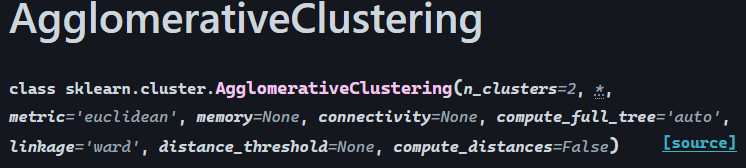

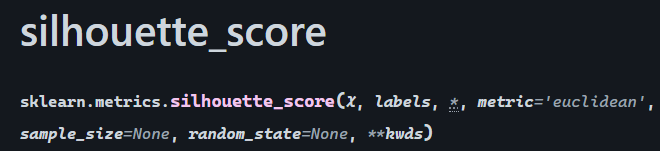

In [15]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import AgglomerativeClustering
import seaborn as sns
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [13]:
df = pd.read_csv("milk.csv",index_col=0)

In [21]:
df

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10
CAMEL,87.7,3.5,3.4,4.8,0.71
BISON,86.9,4.8,1.7,5.7,0.90
BUFFALO,82.1,5.9,7.9,4.7,0.78
GUINEA PIG,81.9,7.4,7.2,2.7,0.85


In [14]:
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)
scl_df.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,0.948806,-1.009291,-0.903208,1.542217,-1.037554
ORANGUTAN,0.821407,-1.344603,-0.660619,1.040773,-1.259945
MONKEY,0.813445,-1.121062,-0.738247,1.263637,-1.381249
DONKEY,0.964731,-1.260775,-0.864394,1.152205,-0.936467
HIPPO,0.972694,-1.568145,-0.563583,0.149319,-1.542988


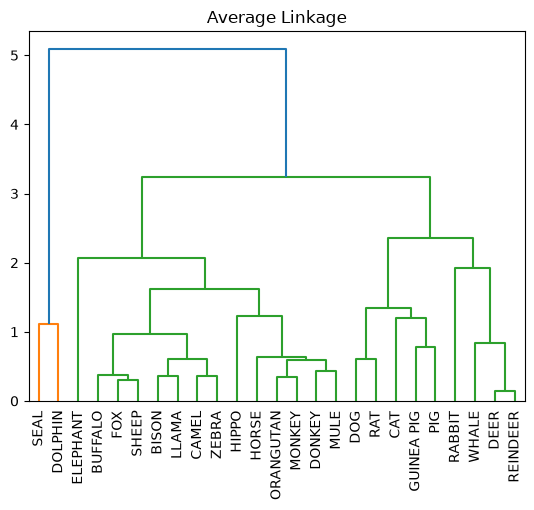

In [11]:
dendrogram(linkage(scl_df, method="average"),labels=( scl_df.index))
plt.title("Average Linkage")
plt.xticks(rotation=90)
plt.show()

In [20]:
clusters = [2,3,4,5,6,7]
scores = []
for i in clusters:
    hc = AgglomerativeClustering(n_clusters=i)
    hc.fit(scl_df)
    scores.append([i, silhouette_score(scl_df, hc.labels_)])
df_scores = pd.DataFrame(scores, columns=["clusters","score"])
df_scores.sort_values(by="score",ascending=False)

,clusters,score
1,3,0.539160
0,2,0.525851
2,4,0.443481
3,5,0.398301
5,7,0.380407
4,6,0.375007


In [ ]:
df_scores = pd.DataFrame(scores, columns=["clusters","score"])
df_scores.sort_values(by="score",ascending=False)
data = scl_df.copy()
data ["Cluster"] = hc.labels_
data.sort_values("Cluster")

In [27]:
hc = AgglomerativeClustering(n_clusters=3)
hc.fit(scl_df)
hc.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1,
       1, 2, 2])

In [25]:
from sklearn.decomposition import PCA

In [30]:
pca = PCA().set_output(transform='pandas')
pca_data = pca.fit_transform(scl_df)
pca_data.head()

,pca0,pca1,pca2,pca3,pca4
Animal,,,,,
HORSE,2.435175,-0.231478,0.330150,0.307664,0.048184
ORANGUTAN,2.258736,-0.693148,0.029035,-0.081057,-0.000532
MONKEY,2.335861,-0.663328,0.101257,0.247997,0.010109
DONKEY,2.318677,-0.273815,0.109881,-0.092873,-0.006769
HIPPO,2.060294,-1.019199,-0.762436,-0.510091,0.029382


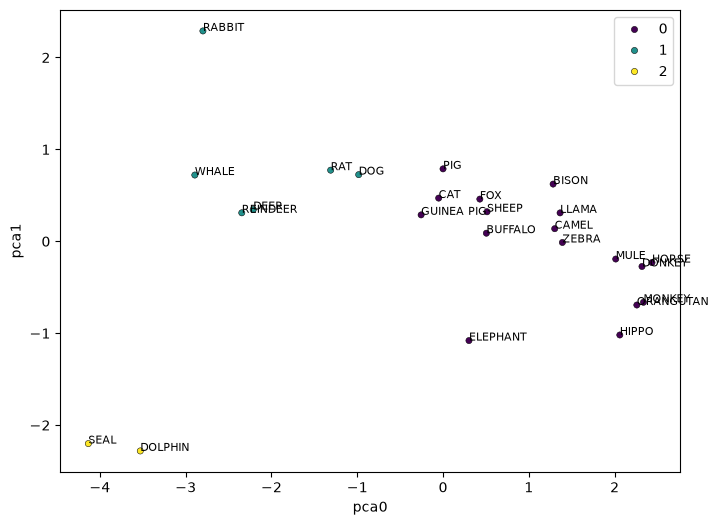

In [41]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data = pca_data, x="pca0", y="pca1",hue=hc.labels_,palette='viridis',s=20, edgecolor='k')
for i in range(len(df)):
    plt.text(pca_data["pca0"].iloc[i],pca_data["pca1"].iloc[i],df.index[i], fontsize=8)
plt.show()